# Stage 1: First look at FastF1 data
Loaded the 2022 Silverstone qualifying data and extracted the fastest lap's telemetry.
Then plotted the speed trace and track map

In [1]:
import fastf1
import matplotlib.pyplot as plt

fastf1.Cache.enable_cache('../cache')

Matplotlib is building the font cache; this may take a moment.
c:\Users\Ryan\Documents\f1-lapsim\.venv\Lib\site-packages\fastf1\req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "


In [12]:
session = fastf1.get_session(2022, 'Great Britain', 'Q')
session.load()

core           INFO 	Loading data for British Grand Prix - Qualifying [v3.9.0]
req            INFO 	Using cached data for session_info


req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['55', '1', '16', '11', '44', '4', '14', '63', '24', '6', '10', '77', '22', '3', '31', '23', '20', '5', '47', '18']


In [19]:
lap = session.laps.pick_fastest()
tel = lap.get_telemetry()

print(lap['Driver'], lap['LapTime'])
tel.head()

# =================================
# Silverstone 2022 had a wet qualifying,
# the fastest lap of the session was not
# Sainz, checking the tire compound
# =================================

print(lap['Compound'], lap['TyreLife'])
print(lap.get_weather_data()[['AirTemp', 'TrackTemp', 'Rainfall']])

VER 0 days 00:01:39.129000
INTERMEDIATE 9.0
AirTemp       14.4
TrackTemp     20.5
Rainfall     False
Name: 31, dtype: object


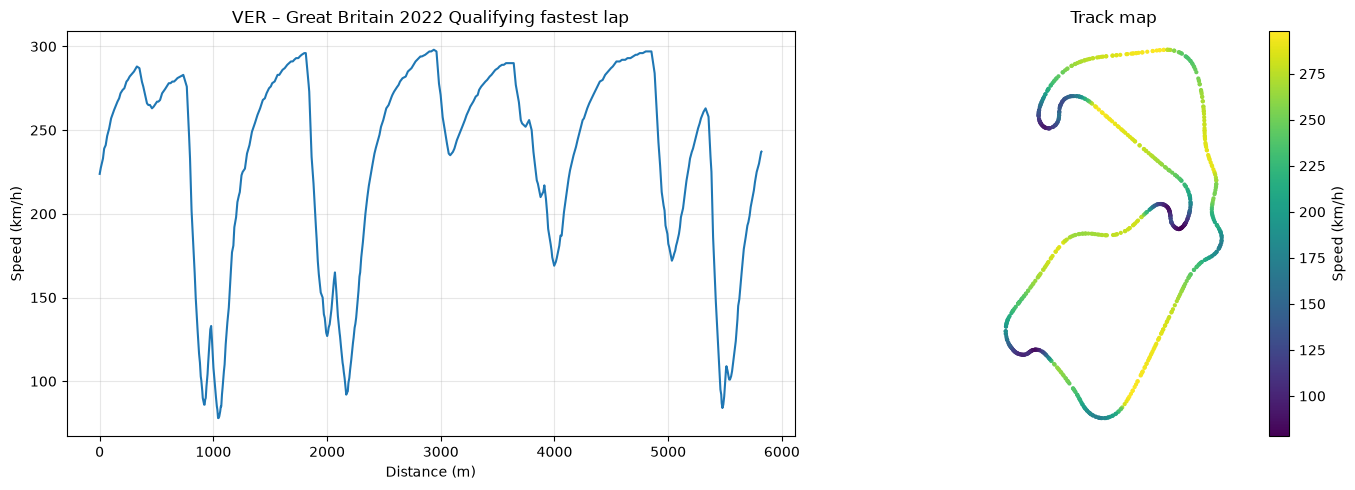

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# =================================
# Distance vs Speed plot
# =================================

ax1.plot(tel['Distance'], tel['Speed'])
ax1.set_xlabel('Distance (m)')
ax1.set_ylabel('Speed (km/h)')
ax1.set_title(f"{lap['Driver']} – Great Britain 2022 Qualifying fastest lap")
ax1.grid(alpha=0.3)

# =================================
# Track map diagram
# =================================

sc = ax2.scatter(tel['X'], tel['Y'], c=tel['Speed'], cmap='viridis', s=4)
ax2.set_aspect('equal')
ax2.axis('off')
fig.colorbar(sc, ax=ax2, label='Speed (km/h)')
ax2.set_title('Track map')

plt.tight_layout()
plt.savefig('../figures/01_speed_trace.png', dpi=200)
plt.show()